<a href="https://colab.research.google.com/github/Poliba-Las-Palmas/CI_CNN/blob/main/CNN_classifier_for_CIFAR_10_simplified.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## CIFAR-10 Dataset
CIFAR-10 is a well-known dataset of labeled images used for training and evaluating computer vision models, particularly for image classification tasks.

The dataset consists of 60,000 color images in 10 classes (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, and truck).

<img src="https://production-media.paperswithcode.com/datasets/4fdf2b82-2bc3-4f97-ba51-400322b228b1.png" width=500px>

The images are 32x32 pixels in size, and each pixel is represented by a color value (red, green, and blue) with 8 bits of precision.

The dataset is well-balanced, with an equal number of images in each class.

The CIFAR-10 dataset has become a benchmark for evaluating the performance of deep learning models for image classification tasks. Many state-of-the-art convolutional neural networks have been trained and evaluated on the CIFAR-10 dataset, including popular architectures such as VGG, ResNet, and Inception.


## Speed up training time by using a GPU CUDA
Since images have a size of (32x32x3), it's common practice to use CUDA tensors, which are similar to typical tensors but are optimized for computation on GPUs.

In [ ]:
# Import libraries
import torch
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# PyTorch dataset
from torchvision import datasets #to load most common datasets
import torchvision.transforms as transforms #to apply transformations to the data (e.g., convert images to tensors)
from torch.utils.data.sampler import SubsetRandomSampler  #to create a sampler that samples elements randomly from a given list of indices

# PyTorch model
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [ ]:
# check if CUDA is available
train_on_gpu = torch.cuda.is_available()

if not train_on_gpu:
    print('CUDA is not available.  Training on CPU ...')
else:
    print('CUDA is available!  Training on GPU ...')

CUDA is not available.  Training on CPU ...


---
## Load the Data

In [ ]:
# number of subprocesses to use for data loading
num_workers = 0
# how many samples per batch to load
batch_size = 20
# percentage of training set to use as validation
valid_size = 0.2

In [ ]:
# same transformation for training, validation and test data (no data augmentation)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))  # normalize pixel values from [0, 1] to [-1, 1]
])

In [ ]:
# choose the training and test datasets
train_data = datasets.CIFAR10('data', train=True,
                              download=True, transform=transform)
test_data = datasets.CIFAR10('data', train=False,
                             download=True, transform=transform)

In [ ]:
# train_test_split splits these indices into two groups:
# - train_idx: indices used for the training set
# - valid_idx: indices used for the validation set
#
# test_size=valid_size specifies the number of samples
# that should be assigned to the validation set.
from sklearn.model_selection import train_test_split
train_idx, valid_idx = train_test_split(range(len(train_data)), test_size=valid_size)

In [ ]:
# Define samplers to select which indices of the dataset will be used
# for training and validation batches.
# train_sampler randomly samples only the examples in train_idx,
# while valid_sampler randomly samples only the examples in valid_idx.
train_sampler = SubsetRandomSampler(train_idx)
valid_sampler = SubsetRandomSampler(valid_idx)

In [ ]:
# prepare data loaders (load data from the different splits) (combine dataset and sampler)
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size,
    sampler=train_sampler, num_workers=num_workers)
valid_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size,
    sampler=valid_sampler, num_workers=num_workers)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,
    num_workers=num_workers)

In [ ]:
# specify the image classes
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

### Visualize a Batch of Training Data

In [ ]:
# helper function to un-normalize and display an image
def imshow(img):
    img = img / 2 + 0.5  # unnormalize (from -1, 1) to (0, 1)
    plt.imshow(np.transpose(img, (1, 2, 0)))  # convert from Tensor to Image (C, H, W) to (H, W, C)

In [ ]:
# obtain one batch of training images
dataiter = iter(train_loader) # create an itarable object from the train_loader
images, labels = next(dataiter) # get the first batch of images and labels from the train_loader
images = images.numpy() # convert images to numpy for display
images.shape # (number of examples: 20, number of channels: 3, pixel sizes: 32x32)

(20, 3, 32, 32)

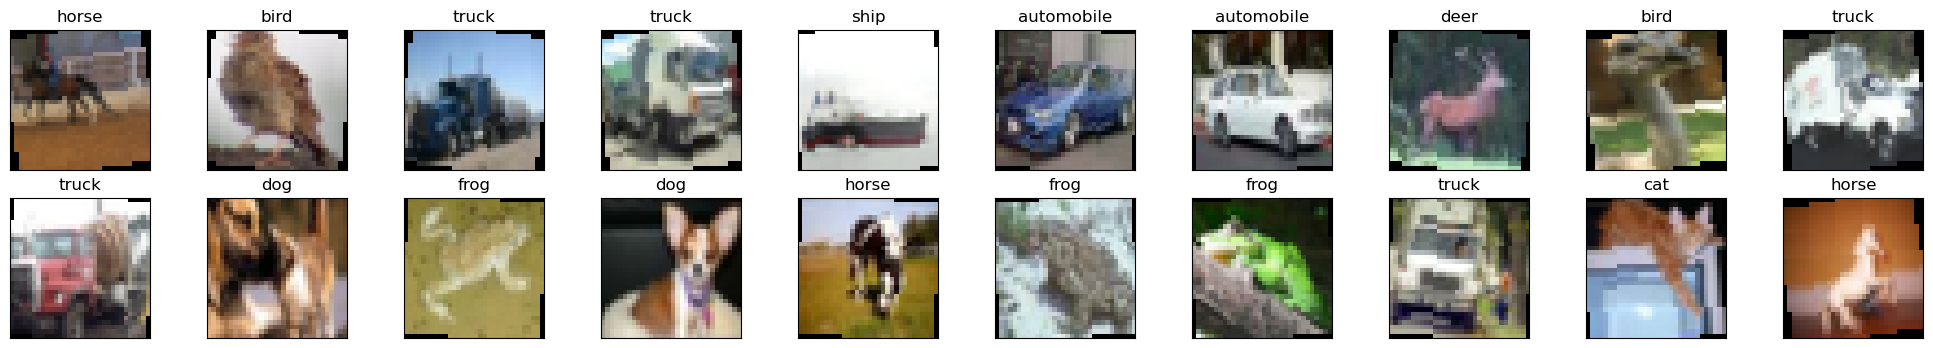

In [ ]:
# plot the images in the batch, along with the corresponding labels
fig = plt.figure(figsize=(25, 4))
# display 20 images
for idx in np.arange(20):
    ax = fig.add_subplot(2, int(20/2), idx+1, xticks=[], yticks=[])
    imshow(images[idx])
    ax.set_title(classes[labels[idx]])

In [ ]:
# define the CNN architecture
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()

        # First convolutional layer
        # Input image: 3 channels, 32x32 pixels
        # Output: 16 feature maps, still 32x32 because padding=1
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        # Second convolutional layer
        # Input: 16 feature maps
        # Output: 32 feature maps
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Third convolutional layer
        # Input: 32 feature maps
        # Output: 64 feature maps
        self.conv3 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # Max pooling layer
        # Reduces height and width by half
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Fully connected layer
        # After 3 pooling operations:
        # 32x32 -> 16x16 -> 8x8 -> 4x4
        # Final tensor has shape: 64 x 4 x 4
        self.fc1 = nn.Linear(64 * 4 * 4, 500)

        # Output layer
        # 10 output neurons, one for each class
        self.fc2 = nn.Linear(500, 10)

        # Dropout layer
        # Randomly disables 25% of neurons during training
        # This helps reduce overfitting
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        # add sequence of convolutional and max pooling layers
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        # flatten image input into a vector
        x = x.view(-1, 64 * 4 * 4)
        # add dropout layer
        x = self.dropout(x)
        # add 1st hidden layer, with relu activation function
        x = F.relu(self.fc1(x))
        # add dropout layer
        x = self.dropout(x)
        # add 2nd hidden layer, with relu activation function
        x = self.fc2(x)
        return x

In [ ]:
# create a complete CNN
model = Net()
model

Net(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1024, out_features=500, bias=True)
  (fc2): Linear(in_features=500, out_features=10, bias=True)
  (dropout): Dropout(p=0.25, inplace=False)
)

In [ ]:
# move tensors to GPU if CUDA is available
if train_on_gpu:
    model.cuda()

### Specify Loss Function and Optimizer


In [ ]:
# specify loss function (categorical cross-entropy)
criterion = nn.CrossEntropyLoss()

# specify optimizer
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

# alternatives to compare:
# optimizer = optim.Adam(model.parameters(), lr=0.001)
# optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

---
## Train the Network


In [ ]:
# number of epochs to train the model
n_epochs = 30

valid_loss_min = np.inf # track change in validation loss to save the best model

for epoch in range(1, n_epochs+1):

    # keep track of training and validation loss
    train_loss = 0.0
    valid_loss = 0.0

    ###################
    # train the model #
    ###################
    model.train()
    for data, target in train_loader:
        # move tensors to GPU if CUDA is available
        if train_on_gpu:
            data, target = data.cuda(), target.cuda()
        # clear the gradients of all optimized variables
        optimizer.zero_grad()
        # forward pass: compute predicted outputs by passing inputs to the model
        output = model(data)
        # calculate the batch loss
        loss = criterion(output, target)
        # backward pass: compute gradient of the loss with respect to model parameters
        loss.backward()
        # perform a single optimization step (parameter update)
        optimizer.step()
        # update training loss
        train_loss += loss.item()*data.size(0)

    ######################
    # validate the model #
    ######################
    model.eval()
    for data, target in valid_loader:
        # move tensors to GPU if CUDA is available
        if train_on_gpu:
            data, target = data.cuda(), target.cuda()
        # forward pass: compute predicted outputs by passing inputs to the model
        output = model(data)
        # calculate the batch loss
        loss = criterion(output, target)
        # update average validation loss
        valid_loss += loss.item()*data.size(0)

    # calculate average losses
    train_loss = train_loss/len(train_loader.sampler)
    valid_loss = valid_loss/len(valid_loader.sampler)

    # print training/validation statistics
    print('Epoch: {} \tTraining Loss: {:.6f} \tValidation Loss: {:.6f}'.format(
        epoch, train_loss, valid_loss))

    # save model if validation loss has decreased
    if valid_loss <= valid_loss_min:
        print('Validation loss decreased ({:.6f} --> {:.6f}).  Saving model ...'.format(
        valid_loss_min,
        valid_loss))
        torch.save(model.state_dict(), 'model_cifar.pt')
        valid_loss_min = valid_loss

###  Load the Model with the Lowest Validation Loss

In [ ]:
model.load_state_dict(torch.load('model_cifar.pt'))

/var/folders/zk/btw393hs7q18f9bm91yr0_wc0000gn/T/ipykernel_61220/689547942.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('model_cifar.

<All keys matched successfully>

---
## Test the Trained Network


In [ ]:
# track test loss
test_loss = 0.0
class_correct = list(0. for i in range(10))
class_total = list(0. for i in range(10))

model.eval()
# iterate over test data
for data, target in test_loader:
    # move tensors to GPU if CUDA is available
    if train_on_gpu:
        data, target = data.cuda(), target.cuda()
    # forward pass: compute predicted outputs by passing inputs to the model
    output = model(data)
    # calculate the batch loss
    loss = criterion(output, target)
    # update test loss
    test_loss += loss.item()*data.size(0)
    # convert output probabilities to predicted class
    _, pred = torch.max(output, 1)
    # compare predictions to true label
    correct_tensor = pred.eq(target.data.view_as(pred))
    correct = np.squeeze(correct_tensor.numpy()) if not train_on_gpu else np.squeeze(correct_tensor.cpu().numpy())
    # calculate test accuracy for each object class
    for i in range(batch_size):
        label = target.data[i]
        class_correct[label] += correct[i].item()
        class_total[label] += 1

# average test loss
test_loss = test_loss/len(test_loader.dataset)
print('Test Loss: {:.6f}\n'.format(test_loss))

for i in range(10):
    if class_total[i] > 0:
        print('Test Accuracy of %5s: %2d%% (%2d/%2d)' % (
            classes[i], 100 * class_correct[i] / class_total[i],
            np.sum(class_correct[i]), np.sum(class_total[i])))
    else:
        print('Test Accuracy of %5s: N/A (no training examples)' % (classes[i]))

print('\nTest Accuracy (Overall): %2d%% (%2d/%2d)' % (
    100. * np.sum(class_correct) / np.sum(class_total),
    np.sum(class_correct), np.sum(class_total)))

Test Loss: 0.676687

Test Accuracy of airplane: 81% (817/1000)
Test Accuracy of automobile: 89% (896/1000)
Test Accuracy of  bird: 61% (618/1000)
Test Accuracy of   cat: 53% (536/1000)
Test Accuracy of  deer: 80% (802/1000)
Test Accuracy of   dog: 66% (667/1000)
Test Accuracy of  frog: 82% (829/1000)
Test Accuracy of horse: 83% (832/1000)
Test Accuracy of  ship: 80% (806/1000)
Test Accuracy of truck: 84% (846/1000)

Test Accuracy (Overall): 76% (7649/10000)


### Visualize Sample Test Results

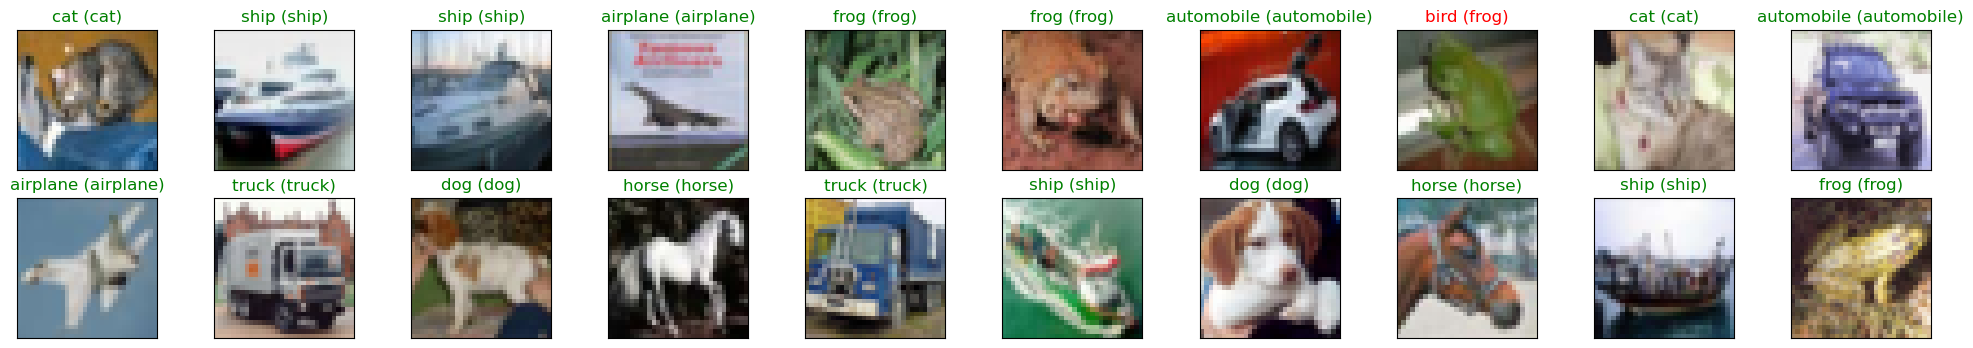

In [ ]:
# obtain one batch of test images
dataiter = iter(test_loader)
images, labels = next(dataiter)
images.numpy()

# move model inputs to cuda, if GPU available
if train_on_gpu:
    images = images.cuda()

# get sample outputs
output = model(images)
# convert output probabilities to predicted class
_, preds_tensor = torch.max(output, 1)
preds = np.squeeze(preds_tensor.numpy()) if not train_on_gpu else np.squeeze(preds_tensor.cpu().numpy())

# plot the images in the batch, along with predicted and true labels
fig = plt.figure(figsize=(25, 4))
for idx in np.arange(20):
    ax = fig.add_subplot(2, int(20/2), idx+1, xticks=[], yticks=[])
    imshow(images[idx] if not train_on_gpu else images[idx].cpu())
    ax.set_title("{} ({})".format(classes[preds[idx]], classes[labels[idx]]),
                 color=("green" if preds[idx]==labels[idx].item() else "red"))